# Super-resolution: evidence, degradation and paired comparisons
Compare bicubic interpolation, a bottleneck autoencoder and a compact residual
pixel-shuffle model under a shared 4× task. [Model design](../docs/11_image_restoration.md).
Gallery photographs retain their [source attribution](../docs/photo_attributions.md).

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
root = Path.cwd()
while not (root / 'pyproject.toml').exists() and root != root.parent:
    root = root.parent
sys.path.insert(0, str(root / 'src'))
def evidence(study):
    return json.loads((root / 'results' / 'reference' / study / 'metrics.json').read_text())
plt.rcParams.update({'figure.figsize': (7, 4), 'axes.spines.top': False, 'axes.spines.right': False})

In [2]:
m = evidence('super_resolution')
pd.DataFrame([{'model':r['model'],'seed':r.get('seed'),'degradation':r['degradation'],
              'psnr':r['psnr']['mean'],'ssim':r['ssim']['mean']} for r in m['rows']])

,model,seed,degradation,psnr,ssim
0,bicubic,NaN,bicubic,22.138934,0.616082
1,bicubic,NaN,blurred_bicubic,21.810156,0.594391
2,autoencoder,0.0,bicubic,23.153867,0.675776
3,autoencoder,0.0,blurred_bicubic,22.938087,0.655564
4,pixelshuffle_residual,0.0,bicubic,23.868568,0.713521
5,pixelshuffle_residual,0.0,blurred_bicubic,23.529371,0.688587
6,autoencoder,1.0,bicubic,23.153404,0.675774
7,autoencoder,1.0,blurred_bicubic,22.937216,0.655464
8,pixelshuffle_residual,1.0,bicubic,23.865768,0.713748
9,pixelshuffle_residual,1.0,blurred_bicubic,23.531557,0.688934


## Pixel shuffle is a reshape with spatial semantics
Four low-resolution feature channels become one channel at twice the resolution.
The learned convolutions produce subpixel predictions; reshaping itself invents no information.

In [3]:
import torch
from torch.nn.functional import pixel_shuffle
features = torch.arange(16.).reshape(1,4,2,2)
print('Subpixel feature channels:',features[0].numpy())
print('Reshaped output:',pixel_shuffle(features,2)[0,0].numpy())

Subpixel feature channels: [[[ 0.  1.]
  [ 2.  3.]]

 [[ 4.  5.]
  [ 6.  7.]]

 [[ 8.  9.]
  [10. 11.]]

 [[12. 13.]
  [14. 15.]]]
Reshaped output: [[ 0.  4.  1.  5.]
 [ 8. 12.  9. 13.]
 [ 2.  6.  3.  7.]
 [10. 14. 11. 15.]]


In [4]:
scores = np.load(root/'assets/source_data/super_resolution_per_image_scores.npz')
base = next(r for r in m['rows'] if r['model']=='bicubic' and r['degradation']=='bicubic')
learned = [r for r in m['rows'] if r['model']=='pixelshuffle_residual' and r['degradation']=='bicubic']
delta = np.mean([scores[r['per_image_psnr_key']] for r in learned],axis=0)-scores[base['per_image_psnr_key']]
rng = np.random.default_rng(7)
bootstrap = delta[rng.integers(len(delta),size=(2000,len(delta)))].mean(1)
print('Mean paired improvement (dB):',delta.mean())
print('Image-bootstrap 95% interval:',np.quantile(bootstrap,[.025,.975]))

Mean paired improvement (dB): 1.7282338237762451
Image-bootstrap 95% interval: [1.63989075 1.81791622]


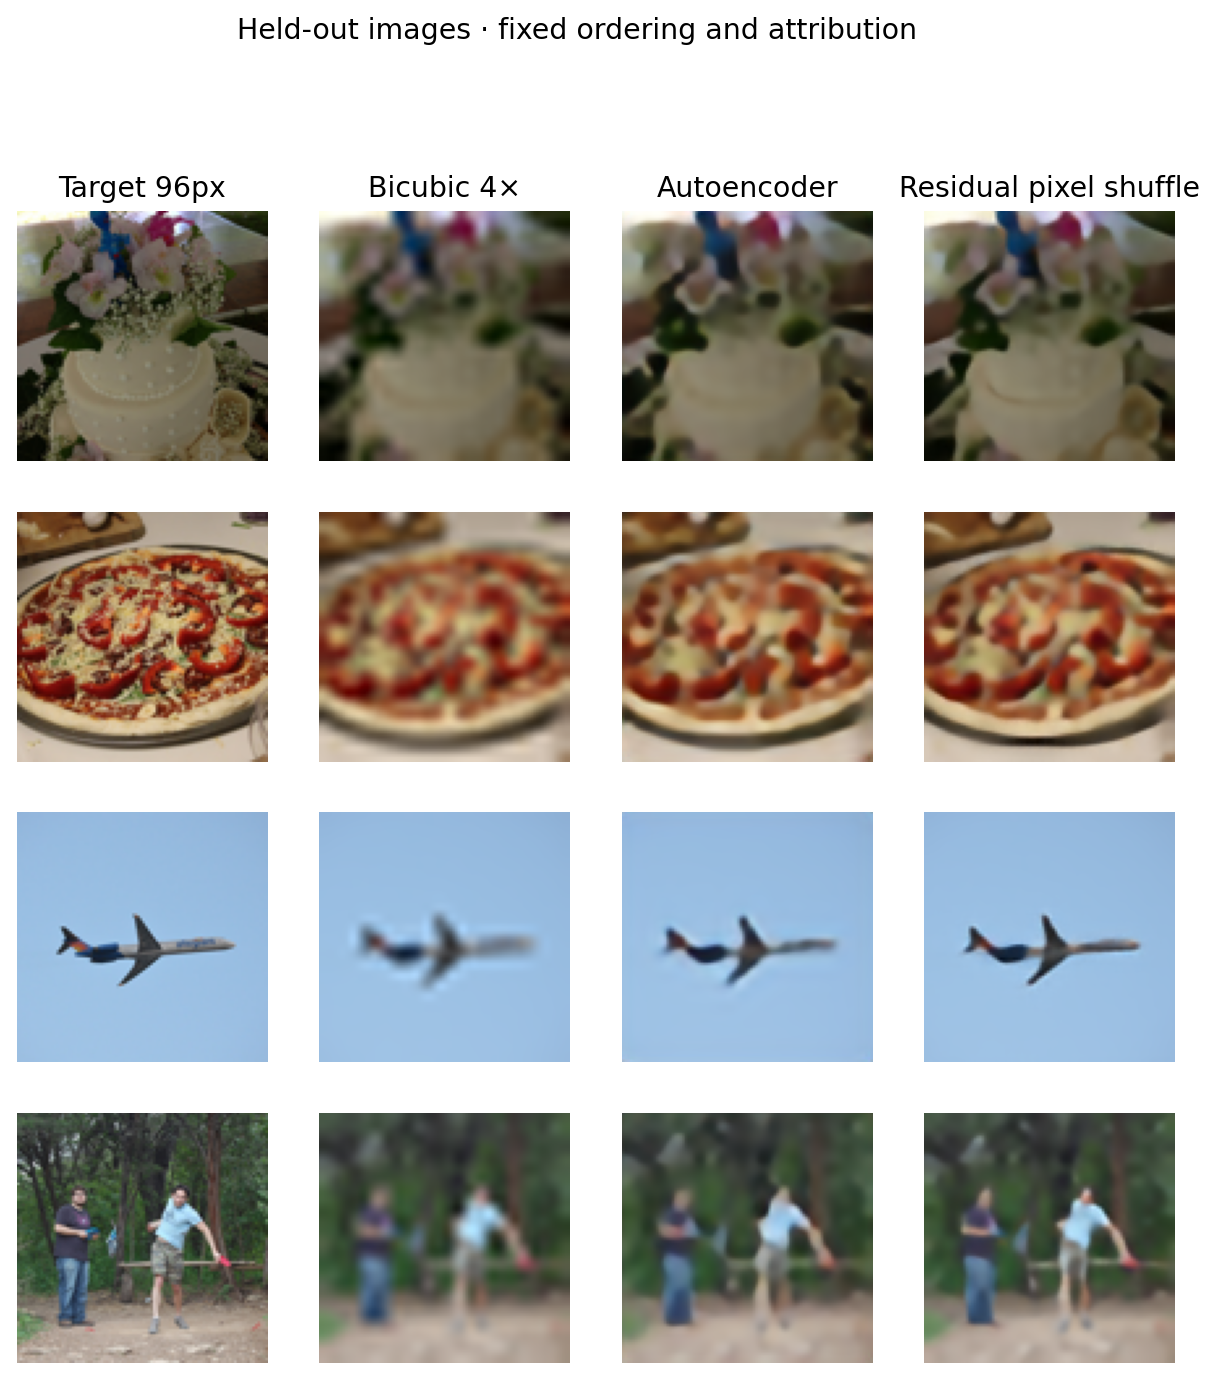

In [5]:
from IPython.display import Image, display
display(Image(filename=str(root/'assets/super_resolution_gallery.png')))

## Worked answer
Why compare each test image with its own baseline? Texture and content affect PSNR
substantially. Paired differences preserve that shared difficulty and isolate the
model contrast. The interval above conditions on these two trained checkpoints;
it does not estimate uncertainty over all possible training seeds or degradation models.